# Fig. 8: trajectories by low-, medium- and high-yield class.

Styling follows Figs. 3, 4, 6 and 7.
Input: traj_b5v10.npz (override with the TRAJ environment variable) with trajectories for
no intervention, APC, PPO (batch mean over seeds), CEM and estimated PAA + BO (batch mean over
10 repeated runs).
Rows: F_s, F_PAA, glucose, PAA, total biomass (kg) and cumulative net penicillin yield (kg,
including discharged broth).
Columns: yield class under no intervention (low < 2,130 kg, n = 55; medium, n = 92;
high >= 3,439 kg, n = 53).
Line = batch mean within the class, band = mean +/- 1.96 SE. Each row shares one y axis.

In [1]:
import sys; sys.path.insert(0, '..')          # repository root, for paths.py
from paths import DATA, OUTD                   # data/ and output/

In [2]:
import os, numpy as np, matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
G = DATA; OUT = OUTD + 'fig8'
INK, GRY = '#23201a', '#8f897d'
plt.rcParams.update({'font.family': ['DejaVu Sans'], 'font.size': 5.5, 'axes.titlesize': 6.5, 'axes.labelsize': 5.5, 'xtick.labelsize': 5.0,
                     'ytick.labelsize': 5.0, 'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
                     'xtick.major.size': 2, 'ytick.major.size': 2, 'legend.fontsize': 5.5, 'mathtext.default': 'regular'})
ARMS = [('No intervention', 'base', GRY, (0, (3, 2.2))), ('APC', 'apc', '#8a3324', '-'), ('BO-tuned controller', 'bo', '#2a7f7a', '-'),
        ('PPO', 'rl', '#c9a227', '-'), ('CEM', 'shcem', '#1f4e79', '-')]
tr = np.load(G + os.environ.get('TRAJ', 'traj_b5v10.npz'), allow_pickle=True)   # traj_b5v10 adds volume (V), biomass (XV) and net yield (NY)
FR = tr['frac'] * 100; NB = 200; CLS = tr['cls']
CL = [('Low yield', 0), ('Medium yield', 1), ('High yield', 2)]
ROW = [('Fs_u', '(a)', '$F_s$ (L h$^{-1}$)'), ('Fpaa_u', '(b)', '$F_{PAA}$ (L h$^{-1}$)'), ('S', '(c)', 'Glucose (g L$^{-1}$)'),
       ('PAA', '(d)', 'PAA (mg L$^{-1}$)'), ('XV', '(e)', 'Biomass (kg)'), ('NY', '(f)', 'Penicillin yield (kg)')]   # amounts (kg) rather than concentrations
def get(key, var):
    a = tr[f'{key}_{var}']
    return np.nanmean(a.reshape(-1, NB, a.shape[1]), 0) if a.shape[0] != NB else a
fig = plt.figure(figsize=(17 / 2.54, 20 / 2.54), facecolor='white')
gs = GridSpec(6, 3, figure=fig, hspace=0.22, wspace=0.10, left=0.10, right=0.985, top=0.93, bottom=0.06)
axs = np.array([[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(6)])
for r, (var, let, ylab) in enumerate(ROW):
    for ci, (cname, c) in enumerate(CL):
        ax = axs[r, ci]
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
        for sp in ('left', 'bottom'): ax.spines[sp].set_color(INK)
        ax.tick_params(colors=INK)
        for name, key, col, ls in ARMS:
            A = get(key, var)[CLS == c]; A = A[np.isfinite(A).all(1)]
            m = A.mean(0); se = A.std(0, ddof=1) / np.sqrt(len(A))
            ax.fill_between(FR, m - 1.96 * se, m + 1.96 * se, color=col, alpha=.15, lw=0, zorder=2)
            ax.plot(FR, m, color=col, ls=ls, lw=0.8, zorder=3, label=name)
        if var == 'PAA': ax.axhline(2400, color=INK, lw=0.4, ls=(0, (1, 1.2)), zorder=1)
        ax.set_xlim(0, 100)
        if r == 0: ax.set_title(f'{cname} (n = {int((CLS == c).sum())})', fontweight='bold', color=INK, pad=4)
        if ci == 0:
            ax.set_ylabel(ylab, color=INK)
            ax.text(-0.30, 1.0, let, transform=ax.transAxes, fontsize=6.5, fontweight='bold', color=INK, va='bottom', ha='left')
        else: ax.tick_params(labelleft=False)
        if r < len(ROW) - 1: ax.tick_params(labelbottom=False)
        else: ax.set_xlabel('Batch time (% of batch duration)', color=INK)
for r in range(6):
    lo = min(a.get_ylim()[0] for a in axs[r]); hi = max(a.get_ylim()[1] for a in axs[r])
    for a in axs[r]: a.set_ylim(lo, hi)
hd, lb = axs[0, 0].get_legend_handles_labels()
fig.legend(hd, lb, loc='upper center', ncol=5, frameon=False, bbox_to_anchor=(0.54, 0.995), handlelength=2.2)
for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}.{ext}', facecolor='white', **kw)
print('Saved', OUT)
for var, *_ in ROW:
    for cname, c in CL:
        print(f'{var:7s} {cname:13s} end ' + ' · '.join(f'{n.split()[0]} {np.nanmean(get(k, var)[CLS == c], 0)[-1]:.3g}' for n, k, *_ in ARMS) +
              ' | max ' + ' · '.join(f'{np.nanmax(np.nanmean(get(k, var)[CLS == c], 0)):.3g}' for n, k, *_ in ARMS))

Saved ../output/fig8
Fs_u    Low yield     end No 86.2 · APC 86.2 · BO-tuned 140 · PPO 151 · CEM 150 | max 105 · 105 · 140 · 151 · 158
Fs_u    Medium yield  end No 84.6 · APC 84.6 · BO-tuned 135 · PPO 141 · CEM 159 | max 111 · 111 · 135 · 143 · 163
Fs_u    High yield    end No 112 · APC 112 · BO-tuned 177 · PPO 160 · CEM 146 | max 129 · 129 · 177 · 170 · 152
Fpaa_u  Low yield     end No 11.3 · APC 5.84 · BO-tuned 5.67 · PPO 6.11 · CEM 9.89 | max 11.3 · 8.51 · 9.78 · 9.99 · 9.89
Fpaa_u  Medium yield  end No 10.2 · APC 6.44 · BO-tuned 6.63 · PPO 8.15 · CEM 10.2 | max 10.3 · 9.28 · 9.76 · 9.99 · 10.2


Fpaa_u  High yield    end No 9.53 · APC 7.06 · BO-tuned 5.5 · PPO 9.48 · CEM 10.8 | max 10 · 9.71 · 10.2 · 9.99 · 11.2
S       Low yield     end No 55.8 · APC 0.00188 · BO-tuned 1.45 · PPO 4.53 · CEM 0.0019 | max 55.8 · 2.01 · 2.01 · 4.53 · 2.01
S       Medium yield  end No 18.8 · APC 0.00166 · BO-tuned 0.56 · PPO 1.75 · CEM 0.00198 | max 18.8 · 2.04 · 2.04 · 2.04 · 2.04
S       High yield    end No 4.62 · APC 0.002 · BO-tuned 3.98 · PPO 5.06 · CEM 0.00195 | max 4.62 · 2.11 · 3.98 · 5.06 · 2.11


PAA     Low yield     end No 7.93e+03 · APC 1.2e+03 · BO-tuned 1.54e+03 · PPO 1.59e+03 · CEM 639 | max 7.93e+03 · 1.6e+03 · 1.6e+03 · 1.7e+03 · 1.6e+03
PAA     Medium yield  end No 4.03e+03 · APC 1.2e+03 · BO-tuned 1.02e+03 · PPO 1.16e+03 · CEM 673 | max 4.03e+03 · 1.59e+03 · 1.59e+03 · 1.59e+03 · 1.59e+03
PAA     High yield    end No 2.24e+03 · APC 1.2e+03 · BO-tuned 813 · PPO 1.26e+03 · CEM 642 | max 2.24e+03 · 1.59e+03 · 1.59e+03 · 1.59e+03 · 1.59e+03
XV      Low yield     end No 1.28e+03 · APC 1.69e+03 · BO-tuned 1.96e+03 · PPO 2.04e+03 · CEM 2.27e+03 | max 1.92e+03 · 1.93e+03 · 1.98e+03 · 2.04e+03 · 2.28e+03


XV      Medium yield  end No 1.6e+03 · APC 1.74e+03 · BO-tuned 2e+03 · PPO 2.07e+03 · CEM 2.32e+03 | max 1.95e+03 · 1.95e+03 · 2.01e+03 · 2.07e+03 · 2.32e+03
XV      High yield    end No 1.86e+03 · APC 1.9e+03 · BO-tuned 2.24e+03 · PPO 2.29e+03 · CEM 2.26e+03 | max 2e+03 · 2e+03 · 2.24e+03 · 2.29e+03 · 2.26e+03
NY      Low yield     end No 1.77e+03 · APC 3.26e+03 · BO-tuned 3.46e+03 · PPO 3.52e+03 · CEM 3.98e+03 | max 1.88e+03 · 3.26e+03 · 3.46e+03 · 3.52e+03 · 3.98e+03
NY      Medium yield  end No 2.84e+03 · APC 3.34e+03 · BO-tuned 3.57e+03 · PPO 3.65e+03 · CEM 4.04e+03 | max 2.84e+03 · 3.34e+03 · 3.57e+03 · 3.65e+03 · 4.04e+03


NY      High yield    end No 3.79e+03 · APC 3.9e+03 · BO-tuned 3.99e+03 · PPO 4.01e+03 · CEM 4.37e+03 | max 3.79e+03 · 3.9e+03 · 3.99e+03 · 4.01e+03 · 4.37e+03


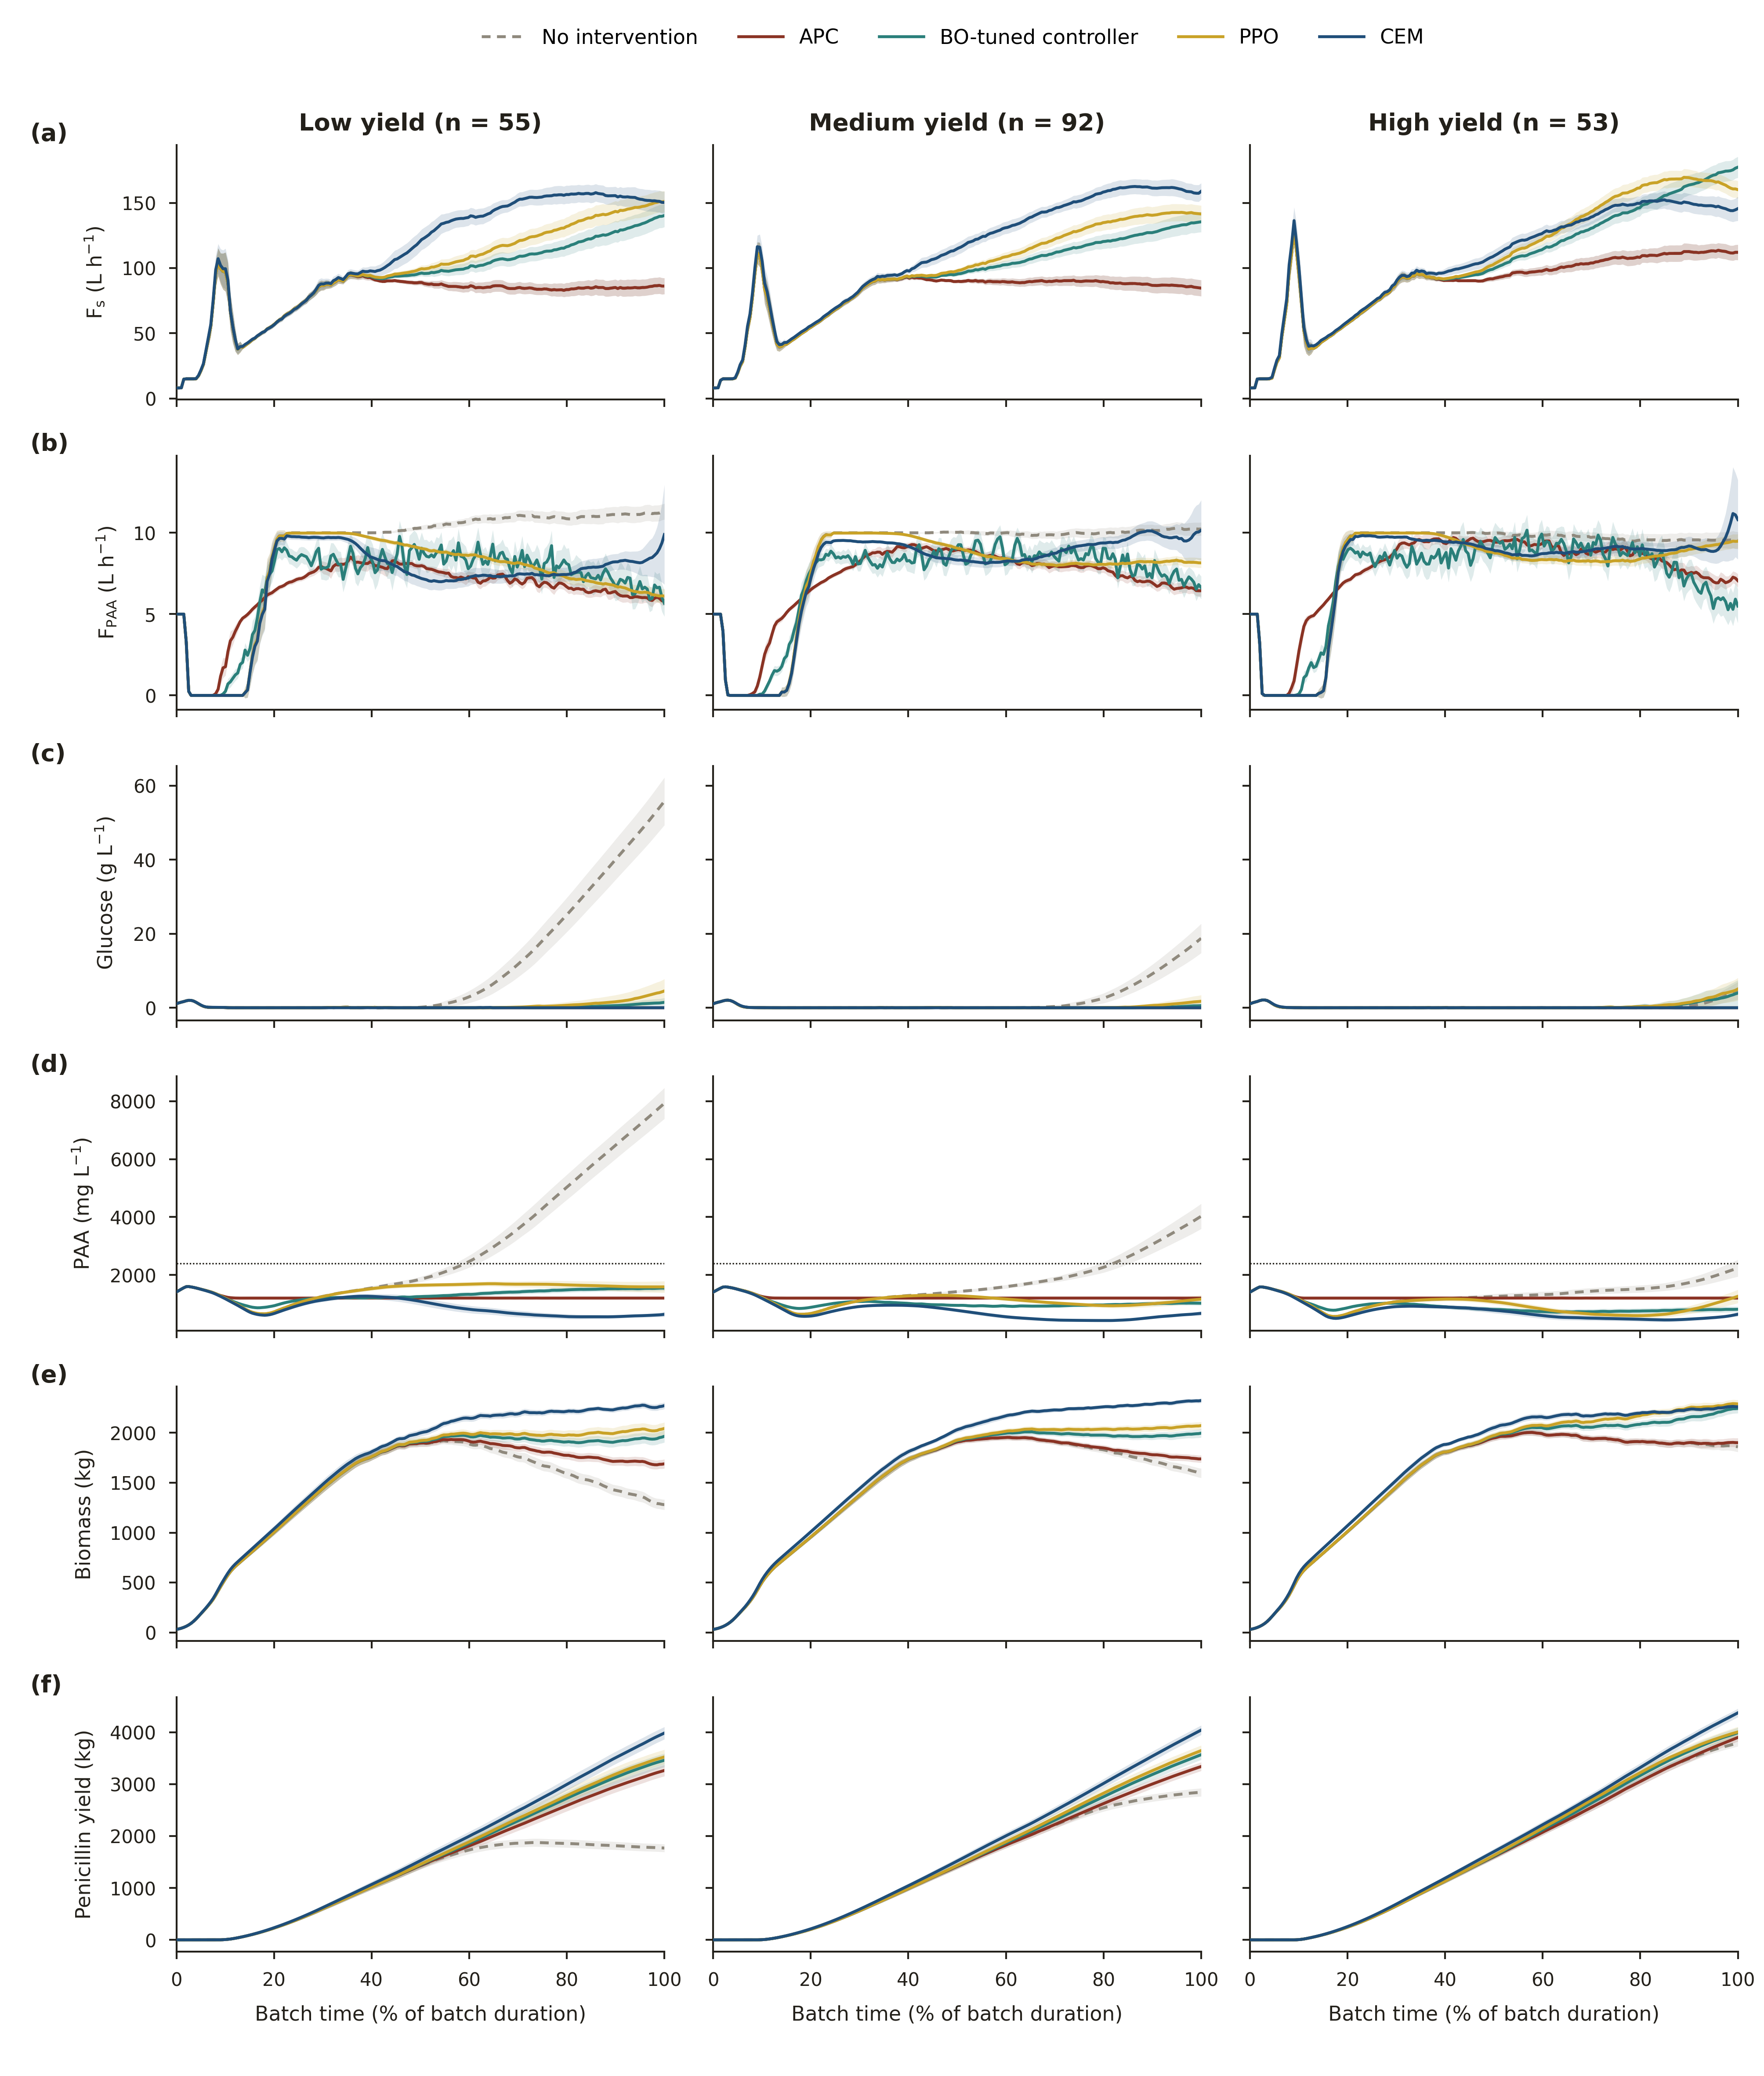

In [3]:
from IPython.display import Image
Image(OUTD + 'fig8.png', width=900)